# 15 — What a MW online is worth, and what a request costs to carry

A probability of operation is not a decision. A portfolio manager weighs expected MW online, when they come, what they earn, and what it costs to keep a request alive to the next gate. This notebook builds that layer **explicitly**: every value input is either parsed from a public file on disk (EIA's wholesale prices, the PJM market monitor's capacity revenue and accreditation tables, EIA generation and capacity for capacity factors, LBNL's PJM interconnection costs) or stated as an assumption in `results/value_assumptions.csv` with a low / base / high range and a source. The value is an *index* for comparing requests and books, not a valuation: no discounting, no financing, no tax detail beyond a credit on/off. It is then applied to the test cohort to give each request an expected value and the cohort an expected MW-online path, with a sensitivity grid.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/raw/value/ice_electric-2017final.xlsx … 2025final.xlsx` | EIA, ICE daily hub prices (public domain) |
| in | `data/raw/value/2024-som-pjm-sec5.pdf` | Monitoring Analytics, 2024 State of the Market, Section 5: Table 5-23 (capacity revenue by year), Table 5-13 (ELCC ratings) |
| in | `data/raw/value/irs_notice_2025-42.pdf` | IRS Notice 2025-42: begin-construction rules for wind and solar credits |
| in | `data/raw/lbnl_costs/pjm_costs_2022_clean_data.xlsx` | LBNL, PJM interconnection costs per kW by project |
| in | EIA API, `electricity/electric-power-operational-data` (annual generation by state and fuel, 2024), cached to `data/raw/value/eia_generation_2024.json` | key from `.env`, never printed |
| in | `data/raw/eia860m/eia860m_2026-07.parquet`, `data/interim/trackA.parquet`, `results/dt_tuning.json`, `results/recalibration.csv` | notebooks 01/04/06/12 |
| out | `results/value_assumptions.csv` | every assumed input with range and source |
| out | `results/energy_prices.csv`, `results/capacity_prices.csv`, `results/capacity_factors.csv`, `results/accreditation.csv` | the parsed inputs |
| out | `results/value_table.csv` | $/MW-year by region × technology × year, low / base / high |
| out | `results/cost_table.csv` | interconnection cost per kW by size band and sunk cost to the next gate |
| out | `results/expected_value_by_request.csv`, `results/expected_mw_online.csv`, `results/value_sensitivity.csv` | the test cohort valued |
| out | `figures/F13_expected_mw_and_value.*`, `figures/15_value_and_cost/*` | F13 and the notebook's figures |
| out | `results/value_checks.csv` | this notebook's checks |
| in | `data/raw/atb/ATBe_2024_v3.parquet` | NREL Annual Technology Baseline 2024 (v3): CAPEX and O&M per kW (section 8) |
| out | `results/atb_costs.csv`, `results/npv_table.csv`, `results/npv_by_request.csv`, `figures/F26_npv_per_mw.*` | NPV per MW by region × technology × COD year and case; expected NPV of every test request at entry (section 8) |

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, eia_api, paths, plots, value, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "15_value_and_cost"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
YEARS = list(range(2017, 2031))  # the value table's years: test entry years through a ten-year window
WINDOW = 10  # years after entry over which a request is valued
TECHS = list(config.TECH_COLORS)  # Solar, Solar+Battery, Wind, Offshore Wind, Battery, Gas, Other
CASES = ["low", "base", "high"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/15_value_and_cost/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Energy prices: EIA's ICE hub files

Volume-weighted annual on-peak prices per hub (`src/value.ice_hub_prices`). PJM is read at PJM West, CAISO at SP15; ERCOT North is traded in these files only through 2019, so ERCOT's later years are extended by PJM West's year-to-year index from the 2017–2019 ratio — an assumption, recorded as such. Years after 2025 hold the 2025 value.

In [2]:
hubs = value.ice_hub_prices()
energy = pd.DataFrame(index=YEARS)
for region, hub in value.HUB_BY_REGION.items():
    energy[region] = hubs.loc[hub].reindex(YEARS)
ratio = (energy.loc[2017:2019, "ERCOT"] / energy.loc[2017:2019, "PJM"]).mean()
extended = energy["ERCOT"].isna() & energy["PJM"].notna()
energy.loc[extended, "ERCOT"] = energy.loc[extended, "PJM"] * ratio
energy = energy.ffill()  # years beyond the files hold the last observed value
energy.index.name = "year"
energy.round(2).to_csv(paths.RESULTS / "energy_prices.csv")
assumptions = [{"input": "ERCOT energy price 2020 onward", "value": f"PJM West × {ratio:.2f}", "low": "× 0.7", "high": "× 1.3",
                "source": "ERCOT North traded in EIA's ICE files only 2017–2019; ratio of the 2017–2019 means", "verified": "assumption"},
               {"input": "prices after 2025", "value": "held at 2025", "low": "", "high": "", "source": "no forward curve used", "verified": "assumption"}]
print(f"ERCOT/PJM on-peak price ratio 2017–2019: {ratio:.2f}; extended years: {int(extended.sum())}")
energy.round(1).T

ERCOT/PJM on-peak price ratio 2017–2019: 0.77; extended years: 6


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
PJM,36.8,45.2,35.4,25.6,48.5,90.5,42.1,48.4,68.2,68.2,68.2,68.2,68.2,68.2
CAISO,44.3,62.3,42.6,52.0,65.1,100.1,64.8,37.2,30.8,30.8,30.8,30.8,30.8,30.8
ERCOT,27.6,28.4,32.9,19.7,37.3,69.6,32.4,37.2,52.4,52.4,52.4,52.4,52.4,52.4


**Reading this.** The on-peak hub price is the first and largest term of the value. PJM West ran from $36.8/MWh in 2017 to $90.5 in 2022 and $68.2 in 2025; SP15 from $44.3 to $100.1 in 2022 and down to $30.8 in 2025, as California's midday prices collapsed under solar; ERCOT North traded at $27.6–32.9 in 2017–2019, 0.77 of PJM West, and that ratio carries ERCOT's later years. Two things follow for the value index: a request that reaches operation in 2022 is worth far more per MW-year than one that arrives in 2020, and the ERCOT line after 2019 is an assumption, not a price.

## 2. Capacity prices and accreditation

PJM: the market monitor's cleared-UCAP-weighted RPM price by calendar year (Table 5-23, $/MW-day → $/kW-year), and the final 2025/2026 marginal ELCC class ratings (Table 5-13), both parsed from the PDF. CAISO has a bilateral resource-adequacy market whose prices are published by the CPUC; no file could be fetched from here, so the CAISO price is an assumption with a wide range. ERCOT is an energy-only market: capacity price zero, with its scarcity value in the energy price. Accreditation by technology group maps PJM's classes onto the project's seven groups and is used for CAISO as a proxy.

In [3]:
rpm = value.pjm_capacity_revenue()
elcc = value.pjm_elcc_ratings()
capacity_price = pd.DataFrame(index=YEARS)
capacity_price["PJM"] = (rpm.reindex(YEARS) * 365 / 1000).ffill()  # $/MW-day → $/kW-year; after 2026 hold
CAISO_RA_KW_MONTH = {"low": 4.0, "base": 8.0, "high": 12.0}  # $/kW-month, assumption (CPUC Resource Adequacy reports; verify)
capacity_price["CAISO"] = CAISO_RA_KW_MONTH["base"] * 12
capacity_price["ERCOT"] = 0.0
capacity_price.index.name = "year"
capacity_price.round(2).to_csv(paths.RESULTS / "capacity_prices.csv")
accreditation = pd.Series({
    "Solar": float((elcc["Solar Fixed"] + elcc["Solar Tracking"]) / 2), "Solar+Battery": float((elcc["Solar Tracking"] + elcc["4-hr Storage"]) / 2),
    "Wind": float(elcc["Onshore Wind"]), "Offshore Wind": float(elcc["Offshore Wind"]), "Battery": float(elcc["4-hr Storage"]),
    "Gas": float((elcc["Gas Combined Cycle"] + elcc["Gas Combustion Turbine"]) / 2), "Other": 0.5}, name="accreditation")
accreditation.to_csv(paths.RESULTS / "accreditation.csv")
assumptions += [
    {"input": "CAISO capacity price", "value": f"${CAISO_RA_KW_MONTH['base']}/kW-month", "low": f"${CAISO_RA_KW_MONTH['low']}", "high": f"${CAISO_RA_KW_MONTH['high']}",
     "source": "CPUC Resource Adequacy reports (not fetched from this machine)", "verified": "assumption — verify"},
    {"input": "ERCOT capacity price", "value": "0", "low": "0", "high": "0", "source": "energy-only market", "verified": "by design"},
    {"input": "PJM capacity price after 2026", "value": "held at 2026 (partial year)", "low": "", "high": "", "source": "Monitoring Analytics 2024 SOM Table 5-23", "verified": "parsed"},
    {"input": "accreditation by technology group", "value": "PJM 2025/26 ELCC class averages", "low": "× 0.7", "high": "× 1.3",
     "source": "Monitoring Analytics 2024 SOM Table 5-13 (Jan 23, 2025 column); applied to CAISO as a proxy", "verified": "parsed; mapping is an assumption"},
]
print(f"PJM capacity revenue, $/kW-year: 2018 {capacity_price.loc[2018, 'PJM']:.1f}, 2024 {capacity_price.loc[2024, 'PJM']:.1f}, "
      f"2025 {capacity_price.loc[2025, 'PJM']:.1f}, 2026 {capacity_price.loc[2026, 'PJM']:.1f}")
display(accreditation.round(2).to_frame().T)
capacity_price.round(1).T

PJM capacity revenue, $/kW-year: 2018 58.1, 2024 16.1, 2025 70.3, 2026 108.2


,Solar,Solar+Battery,Wind,Offshore Wind,Battery,Gas,Other
accreditation,0.12,0.34,0.38,0.62,0.55,0.7,0.5


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
PJM,48.6,58.1,49.5,40.4,48.3,37.7,19.9,16.1,70.3,108.2,108.2,108.2,108.2,108.2
CAISO,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0
ERCOT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Reading this.** PJM's capacity revenue is the most volatile input: $58/kW-year in 2018, $16 in 2024, $70 in 2025 and $108 in 2026 (a partial year), parsed from the market monitor's table. Accreditation decides how much of a plant's nameplate earns it: 12% for solar, 38% for onshore wind, 55% for four-hour storage, 70% for gas, which is why a MW of gas carries several times the capacity value of a MW of solar in PJM. CAISO's $96/kW-year is an assumption with a range of $48–144 and is flagged for verification; ERCOT's zero is by design. These numbers are an index of relative worth, not a forecast of any plant's revenue.

## 3. Capacity factors: EIA generation over EIA-860M nameplate

Annual 2024 net generation by state and fuel from the EIA API (cached as JSON, key never printed) over the operating nameplate by state and technology group from the EIA-860M pull of notebook 01 (July 2026 inventory — a vintage mismatch of up to two years, accepted and stated). The capacity factor for a request is the one of its state and technology group; a state without that technology takes the national value. Storage has no meaningful capacity factor and earns capacity value only.

In [4]:
cache = paths.DATA_RAW / "value" / "eia_generation_2024.json"
FUEL_TO_TECH = {"SUN": "Solar", "WND": "Wind", "NG": "Gas", "NUC": "Nuclear", "COW": "Coal", "HYC": "Hydro", "GEO": "Geothermal"}
if cache.exists():
    gen_rows = json.loads(cache.read_text(encoding="utf-8"))
else:
    key = eia_api.load_api_key()
    url = f"{config.EIA_API_BASE}/electricity/electric-power-operational-data/data/"
    gen_rows, offset = [], 0
    while True:
        page = eia_api._get(url, {"frequency": "annual", "data[]": ["generation"], "facets[sectorid][]": "99",
                                  "facets[fueltypeid][]": list(FUEL_TO_TECH), "start": "2024", "end": "2024",
                                  "length": config.EIA_PAGE_LENGTH, "offset": offset}, key)
        gen_rows += page["response"]["data"]
        offset += config.EIA_PAGE_LENGTH
        if offset >= int(page["response"]["total"]):
            break
    text = json.dumps(gen_rows)
    assert key not in text
    cache.write_text(text, encoding="utf-8")
gen = pd.DataFrame(gen_rows)
gen = gen[(gen["location"].str.len() == 2) & (gen["location"] != "US")].copy()  # states only: the route also carries census regions and "US"
gen["mwh"] = pd.to_numeric(gen["generation"], errors="coerce") * 1000  # thousand MWh → MWh
gen["tech"] = gen["fueltypeid"].map(FUEL_TO_TECH)
gen = gen.groupby(["location", "tech"], as_index=False)["mwh"].sum().rename(columns={"location": "state"})

eia = pd.read_parquet(sorted((paths.RAW_EIA860M).glob("eia860m_*.parquet"))[-1])
eia = eia[eia["status"] == "OP"].copy()
eia["mw"] = pd.to_numeric(eia["nameplate-capacity-mw"], errors="coerce")
eia["tech"] = eia["technology"].map(lambda t: config.EIA_TECHNOLOGY_MAP.get(t, ("Other", ""))[0])
cap = eia.groupby(["stateid", "tech"], as_index=False)["mw"].sum().rename(columns={"stateid": "state"})
cf = value.capacity_factors(gen, cap)
cf = cf[cf["mw"] >= 50]  # a state needs 50 MW of a technology for its factor to mean anything
national = (gen.groupby("tech")["mwh"].sum() / (cap.groupby("tech")["mw"].sum() * value.HOURS_PER_YEAR)).clip(0, 1)
cf.to_csv(paths.RESULTS / "capacity_factors.csv", index=False)
OFFSHORE_CF, OTHER_CF = 0.40, 0.30  # no operating fleet to measure (offshore) or too mixed (other); assumptions
assumptions += [
    {"input": "capacity factors", "value": "2024 generation / July-2026 nameplate, by state × technology", "low": "× 0.85", "high": "× 1.15",
     "source": "EIA API electric-power-operational-data; EIA-860M (notebook 01)", "verified": "computed; vintage mismatch stated"},
    {"input": "offshore wind capacity factor", "value": OFFSHORE_CF, "low": 0.35, "high": 0.45, "source": "no operating U.S. fleet in 2024 data", "verified": "assumption"},
    {"input": "'Other' technology capacity factor", "value": OTHER_CF, "low": 0.2, "high": 0.5, "source": "mixed group", "verified": "assumption"},
]
print(f"state × technology factors: {len(cf)}; national: " + ", ".join(f"{t} {v:.2f}" for t, v in national.round(2).items()))
cf[cf["state"].isin(["TX", "CA", "PA"])].pivot(index="state", columns="tech", values="capacity_factor").round(2)

state × technology factors: 245; national: Battery nan, Coal 0.42, Gas 0.38, Geothermal 0.46, Hydro 0.29, Nuclear 0.88, Offshore Wind nan, Other nan, Solar 0.15, Wind 0.31


tech,Coal,Gas,Geothermal,Hydro,Nuclear,Solar,Wind
state,,,,,,,
CA,0.51,0.25,0.44,0.25,0.90,0.22,0.28
PA,0.29,0.56,NaN,0.13,0.90,0.10,0.22
TX,0.48,0.41,NaN,0.13,0.86,0.14,0.32


**Reading this.** Capacity factors from the data: in Texas, 0.14 for solar, 0.32 for wind, 0.41 for gas; in California 0.22, 0.28 and 0.25; in Pennsylvania 0.10, 0.22 and 0.56. Nationally 0.15 for solar, 0.31 for wind and 0.38 for gas (2024 generation over the July-2026 fleet, which understates factors where capacity grew fast in 2025–2026 — solar most of all). 245 state × technology factors are used; a request whose state lacks its technology takes the national value. Storage earns no energy value here, which undervalues it where arbitrage pays.

## 4. Credits, capture and the value table

Two more stated inputs: the *capture* of the on-peak hub price by technology (solar and wind sell into lower-priced hours than the on-peak average; gas captures it; storage earns capacity value only here), and a production credit for wind and solar that reach operation by the end of 2027 — the deadline IRS Notice 2025-42 sets for projects that have not begun construction by July 4, 2026 — at a stated $/MWh. The value table then follows `src/value.value_per_mw_year` for every region × technology × year under low, base and high multipliers.

In [5]:
CAPTURE = {"Solar": 0.8, "Solar+Battery": 0.85, "Wind": 0.8, "Offshore Wind": 0.85, "Battery": 0.0, "Gas": 1.0, "Other": 0.9}
CREDIT_USD_MWH = 27.5  # production credit for wind and solar, $/MWh; statutory base rate as inflation-adjusted (verify)
CREDIT_LAST_COD_YEAR = 2027  # IRS Notice 2025-42: placed in service by end-2027 unless construction began by 2026-07-04
MULTIPLIER = {"low": {"energy": 0.7, "capacity": 0.5, "credit": 0.0}, "base": {"energy": 1.0, "capacity": 1.0, "credit": 1.0},
              "high": {"energy": 1.3, "capacity": 1.5, "credit": 1.0}}
assumptions += [
    {"input": "capture of the on-peak price", "value": str(CAPTURE), "low": "energy × 0.7", "high": "energy × 1.3", "source": "assumption", "verified": "assumption"},
    {"input": "production credit, wind and solar", "value": f"${CREDIT_USD_MWH}/MWh if operating by {CREDIT_LAST_COD_YEAR}", "low": "0", "high": f"${CREDIT_USD_MWH}",
     "source": "IRC §45 base rate inflation-adjusted (verify the year's rate); deadline from IRS Notice 2025-42 (data/raw/value/irs_notice_2025-42.pdf)", "verified": "deadline from the notice; rate to verify"},
    {"input": "case multipliers", "value": str(MULTIPLIER), "low": "", "high": "", "source": "assumption", "verified": "assumption"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)

cf_lookup = {(r.state, r.tech): r.capacity_factor for r in cf.itertuples()}


def tech_cf(state, tech):
    base = {"Solar": "Solar", "Solar+Battery": "Solar", "Wind": "Wind", "Gas": "Gas"}.get(tech)
    if tech == "Offshore Wind":
        return OFFSHORE_CF
    if tech == "Battery":
        return 0.0
    if base is None:
        return OTHER_CF
    return cf_lookup.get((state, base), float(national.get(base, OTHER_CF)))


def inputs_for(state, cod_year):
    """The value inputs of one request: its state's capacity factors and the credit if it operates in time."""
    return {"energy_price": {r: energy[r].to_dict() for r in TRACK_A},
            "capacity_factor": {t: tech_cf(state, t) for t in TECHS},
            "capture": CAPTURE,
            "capacity_price": {r: capacity_price[r].to_dict() for r in TRACK_A},
            "accreditation": accreditation.to_dict(),
            "credit": {t: (CREDIT_USD_MWH if t in ("Solar", "Solar+Battery", "Wind", "Offshore Wind") and cod_year <= CREDIT_LAST_COD_YEAR else 0.0) for t in TECHS},
            "multiplier": MULTIPLIER}


rows = []
for region in TRACK_A:
    state = {"PJM": "PA", "CAISO": "CA", "ERCOT": "TX"}[region]  # the table is shown for each region's largest state
    for tech in TECHS:
        for year in YEARS:
            rec = {"region": region, "state": state, "tech": tech, "year": year}
            for case in CASES:
                rec[case] = value.value_per_mw_year(region, tech, year, inputs_for(state, year), case)
            rows.append(rec)
value_table = pd.DataFrame(rows)
value_table.round(0).to_csv(paths.RESULTS / "value_table.csv", index=False)
show = value_table[value_table["year"] == 2024].pivot(index="tech", columns="region", values="base").round(-3)
show

region,CAISO,ERCOT,PJM
tech,,,
Battery,53000.0,0.0,9000.0
Gas,149000.0,133000.0,249000.0
Offshore Wind,267000.0,207000.0,250000.0
Other,136000.0,88000.0,123000.0
Solar,120000.0,70000.0,62000.0
Solar+Battery,145000.0,72000.0,68000.0
Wind,175000.0,162000.0,135000.0


**Reading this.** In 2024 and the base case, a MW online is worth about $249,000 a year for gas in PJM, $135,000 for wind and $62,000 for solar; in CAISO solar rises to $120,000 because the capacity price is assumed and the credit applies; in ERCOT, with no capacity price, solar is worth $70,000 and a battery nothing (an admitted gap). The order across technologies is set by capacity factor and accreditation; the order across years by the hub price and PJM's capacity revenue. Every term, its range and its source are in `results/value_assumptions.csv`; the low case halves the capacity value, cuts energy by 30% and removes the credit, the high case does the reverse.

## 5. Costs: interconnection cost per kW and the sunk cost to the next gate

LBNL's PJM data give 1,127 project-level interconnection cost estimates in $2022/kW. The median by size band is the cost exposure of a request of that size; it is applied to CAISO and ERCOT as a proxy (their costs are not in the file) with a wide range. The sunk cost to the next decision gate is a share of that exposure (deposits, studies) plus a fixed study cost — both assumptions with ranges.

In [6]:
costs = value.pjm_cost_table()
by_size = costs.groupby("size_regime", observed=True)["total_cost_per_kw"].agg(["median", "size"]).reindex(config.SIZE_LABELS)
by_size.columns = ["cost_per_kw_median", "n_projects"]
by_size["cost_per_kw_median"] = by_size["cost_per_kw_median"].fillna(costs["total_cost_per_kw"].median())
DEPOSIT_SHARE = {"low": 0.05, "base": 0.10, "high": 0.20}  # share of the interconnection cost committed before the next gate
STUDY_COST = {"low": 50_000, "base": 150_000, "high": 500_000}  # $ per request to the next gate
cost_table = by_size.copy()
for case in CASES:
    cost_table[f"sunk_per_mw_{case}"] = cost_table["cost_per_kw_median"] * 1000 * DEPOSIT_SHARE[case]
cost_table.to_csv(paths.RESULTS / "cost_table.csv")
assumptions += [
    {"input": "interconnection cost per kW outside PJM", "value": "PJM median by size band", "low": "× 0.5", "high": "× 2", "source": "LBNL PJM cost data (no CAISO/ERCOT file)", "verified": "proxy"},
    {"input": "deposit share of interconnection cost to the next gate", "value": DEPOSIT_SHARE["base"], "low": DEPOSIT_SHARE["low"], "high": DEPOSIT_SHARE["high"], "source": "assumption", "verified": "assumption"},
    {"input": "study cost to the next gate, $ per request", "value": STUDY_COST["base"], "low": STUDY_COST["low"], "high": STUDY_COST["high"], "source": "assumption", "verified": "assumption"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)
print(f"{len(costs):,} PJM cost estimates; overall median ${costs['total_cost_per_kw'].median():.0f}/kW, "
      f"network upgrades median ${costs['network_cost_per_kw'].median():.0f}/kW")
cost_table.round(0)

1,127 PJM cost estimates; overall median $61/kW, network upgrades median $39/kW


,cost_per_kw_median,n_projects,sunk_per_mw_low,sunk_per_mw_base,sunk_per_mw_high
size_regime,,,,,
<5,30.0,80,1510.0,3021.0,6041.0
5–<20,38.0,164,1906.0,3813.0,7626.0
20–<100,82.0,517,4084.0,8169.0,16338.0
100–<200,76.0,189,3818.0,7636.0,15271.0
200–<500,44.0,110,2194.0,4387.0,8774.0
≥500,8.0,67,421.0,841.0,1683.0


**Reading this.** PJM's interconnection cost estimates have a median of $61/kW and a long tail (the 75th percentile is $157, the maximum $10,189). By size band the median rises from $30/kW under 5 MW to $82 at 20–100 MW and $76 at 100–200 MW, then falls to $44 at 200–500 MW and $8 above 500 MW — the largest requests in this file are mostly gas and nuclear uprates at existing points of interconnection. The sunk cost to the next gate is a tenth of that exposure per MW (base), $3,000–8,000 per MW, plus $150,000 of studies; it is small next to the expected value of most requests and matters only for the smallest, where it turns a few expected values negative.

## 6. The test cohort valued: expected MW online and expected value per request

The v2 model (notebook 11's choice) is refitted on entrants to 2016 and its yearly P(operation by year 1 … 10) read for every test request, raw and with the rolling level repair of notebook 12 (the 5-year intercept of the request's region and entry year, applied to the whole curve — a simplification stated here). Expected MW online by year is the sum over requests of MW × P(operates in that year); expected value follows `src/value.expected_value` with the request's own state capacity factors, the value table's years from its entry year, and the sunk cost of its size band.

In [7]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
chosen = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
fit = variants.fit_candidate(variants.CANDIDATES[chosen], final, clean, tuning)
curve = discrete_time.predict_both(fit, test, horizons=list(range(1, WINDOW + 1)))[variants.CANDIDATES[chosen]["model"]]
P_raw = curve[list(range(1, WINDOW + 1))].to_numpy()
recal = pd.read_csv(paths.RESULTS / "recalibration.csv")
shift = recal[recal["horizon"] == 5].set_index(["scored_year", "region"])["intercept"]
a = np.array([shift.get((int(y), r), 0.0) for y, r in zip(test["q_year"], test["region"].astype(str))])
P_recal = drift.apply_intercept(P_raw, a[:, None])

records, mw_online = [], {case: {v: np.zeros(WINDOW) for v in ["raw", "recalibrated"]} for case in CASES}
for i, (idx, r) in enumerate(test.iterrows()):
    years_ahead = [int(r["q_year"]) + j for j in range(1, WINDOW + 1)]
    sunk = {case: cost_table.loc[str(r["size_regime"]), f"sunk_per_mw_{case}"] * r["mw"] + STUDY_COST[case] for case in CASES}
    rec = {"project_key": str(r["project_key"]), "region": r["region"], "tech": r["tech"], "state": r["state"], "mw": r["mw"],
           "q_year": int(r["q_year"]), "size_regime": str(r["size_regime"]), "event": int(r["event"]), "duration_years": r["duration_years"],
           "p5_raw": P_raw[i, 4], "p5_recalibrated": P_recal[i, 4]}
    for version, P in [("raw", P_raw), ("recalibrated", P_recal)]:
        increments = np.diff(np.concatenate([[0.0], P[i]]))
        rec[f"expected_mw_online_{version}"] = float(P[i, -1] * r["mw"])
        for case in CASES:
            vals = [value.value_per_mw_year(r["region"], r["tech"], y, inputs_for(r["state"], y), case) for y in years_ahead]
            rec[f"value_{version}_{case}"] = value.expected_value(P[i], r["mw"], vals, sunk[case])
            mw_online[case][version] += increments * r["mw"]
    records.append(rec)
valued = pd.DataFrame(records)
valued.to_csv(paths.RESULTS / "expected_value_by_request.csv", index=False)
path = pd.DataFrame({"years_after_entry": range(1, WINDOW + 1),
                     **{f"expected_mw_{v}": np.cumsum(mw_online["base"][v]) for v in ["raw", "recalibrated"]}})
realised = np.array([float(test.loc[(test["event"] == 1) & (test["duration_years"] <= j), "mw"].sum()) for j in range(1, WINDOW + 1)])
observable = np.array([(((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR) >= j).mean() for j in range(1, WINDOW + 1)])
path["realised_mw_by_end_2024"], path["share_of_cohort_observable"] = realised, observable
path.to_csv(paths.RESULTS / "expected_mw_online.csv", index=False)
print(f"{len(valued):,} requests valued ({(time.time() - START) / 60:.1f} min); cohort MW {test['mw'].sum():,.0f}; "
      f"expected MW online within 5 years: raw {np.cumsum(mw_online['base']['raw'])[4]:,.0f}, recalibrated "
      f"{np.cumsum(mw_online['base']['recalibrated'])[4]:,.0f}; realised by end-2024 within 5 years: {realised[4]:,.0f}")
summary = valued[["mw", "p5_raw", "p5_recalibrated"]].describe().round(3)
summary_value = (valued[["value_raw_base", "value_recalibrated_base", "value_recalibrated_low", "value_recalibrated_high"]] / 1e6).describe().round(2)
display(summary)
summary_value

2,268 requests valued (0.2 min); cohort MW 348,901; expected MW online within 5 years: raw 29,245, recalibrated 25,221; realised by end-2024 within 5 years: 18,772


,mw,p5_raw,p5_recalibrated
count,2268.000,2268.000,2268.000
mean,153.837,0.136,0.112
std,257.664,0.101,0.100
min,0.200,0.004,0.005
25%,20.000,0.071,0.049
50%,80.000,0.112,0.080
75%,200.000,0.171,0.143
max,5120.000,0.722,0.731


,value_raw_base,value_recalibrated_base,value_recalibrated_low,value_recalibrated_high
count,2268.00,2268.00,2268.00,2268.00
mean,19.10,16.15,8.52,19.52
std,39.23,31.28,18.65,40.15
min,-1.32,-1.32,-0.63,-2.84
25%,1.63,1.06,0.52,0.93
50%,7.91,5.46,2.68,6.10
75%,20.84,17.82,8.69,20.97
max,584.76,436.81,290.90,582.07


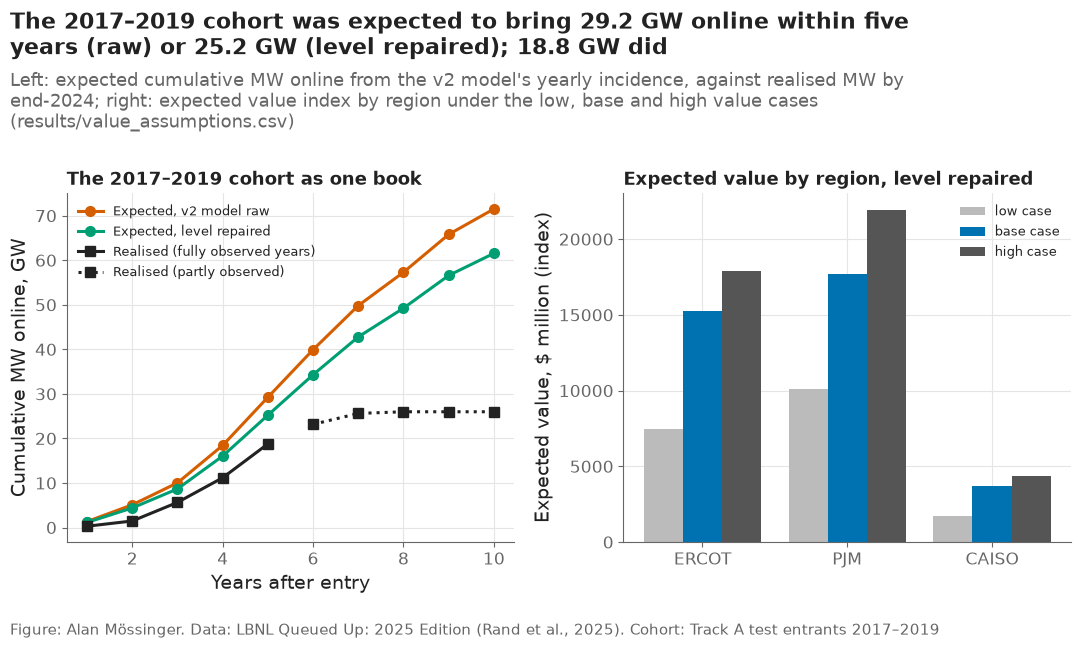

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
ax = axes[0]
ax.plot(path["years_after_entry"], path["expected_mw_raw"] / 1e3, marker="o", color="#D55E00", label="Expected, v2 model raw")
ax.plot(path["years_after_entry"], path["expected_mw_recalibrated"] / 1e3, marker="o", color="#009E73", label="Expected, level repaired")
obs = path[path["share_of_cohort_observable"] >= 0.99]
ax.plot(obs["years_after_entry"], obs["realised_mw_by_end_2024"] / 1e3, marker="s", color=plots.INK, label="Realised (fully observed years)")
part = path[path["share_of_cohort_observable"] < 0.99]
ax.plot(part["years_after_entry"], part["realised_mw_by_end_2024"] / 1e3, marker="s", linestyle=":", color=plots.INK, label="Realised (partly observed)")
ax.set_xlabel("Years after entry")
ax.set_ylabel("Cumulative MW online, GW")
ax.set_title("The 2017–2019 cohort as one book", fontsize=13)
ax.legend(fontsize=9, loc="upper left")
ax = axes[1]
by_region = valued.groupby("region")[[f"value_recalibrated_{c}" for c in CASES]].sum() / 1e6
x = np.arange(len(TRACK_A))
for c_i, case in enumerate(CASES):
    ax.bar(x + (c_i - 1) * 0.27, by_region.loc[TRACK_A, f"value_recalibrated_{case}"], width=0.27,
           color={"low": "#BBBBBB", "base": "#0072B2", "high": "#555555"}[case], label=f"{case} case")
ax.set_xticks(x, TRACK_A)
ax.set_ylabel("Expected value, $ million (index)")
ax.set_title("Expected value by region, level repaired", fontsize=13)
ax.legend(fontsize=9)
r5 = realised[4] / 1e3
plots.finish(fig,
             f"The 2017–2019 cohort was expected to bring {path['expected_mw_raw'].iloc[4] / 1e3:,.1f} GW online within five years "
             f"(raw) or {path['expected_mw_recalibrated'].iloc[4] / 1e3:,.1f} GW (level repaired); {r5:,.1f} GW did",
             "Left: expected cumulative MW online from the v2 model's yearly incidence, against realised MW by end-2024; "
             "right: expected value index by region under the low, base and high value cases (results/value_assumptions.csv)",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F13_expected_mw_and_value",
               "Expected cumulative MW online of the 2017–2019 cohort against realised MW, and the expected value index by region under three value cases.",
               NOTEBOOK)
plt.show()

**Reading this.** The 2017–2019 cohort is 348,901 MW of requests. The v2 model expected 29,245 MW of it to be online within five years; the level repair brings that to 25,221 MW; 18,772 MW actually were by end-2024. The level error of notebook 12, in megawatts, is 56% (raw) or 34% (repaired) over the realised figure — a portfolio built on the raw curve would have been sized for a third more capacity than arrived. Per request, the base-case expected value has a median of $5.5 million and a mean of $16 million (repaired), with a few negative values where the sunk cost exceeds a near-zero probability times a small plant. The right panel puts PJM and ERCOT at $15–18 billion of expected value each and CAISO at $3.6 billion: CAISO's requests are fewer and less likely to be built, and its assumed capacity price does not make up the difference.

## 7. Sensitivity: does the value case change the ranking?

The value index moves a lot between cases; what matters for a book is whether the *order* of requests moves. Spearman correlation of expected value across cases and versions, and the share of the top decile that stays in the top decile.

In [9]:
cols = {f"{v} / {c}": f"value_{v}_{c}" for v in ["raw", "recalibrated"] for c in CASES}
corr = valued[list(cols.values())].corr(method="spearman").round(3)
corr.index = corr.columns = list(cols)
top = {}
base_top = set(valued.nlargest(len(valued) // 10, "value_recalibrated_base")["project_key"])
for label, col in cols.items():
    top[label] = len(base_top & set(valued.nlargest(len(valued) // 10, col)["project_key"])) / len(base_top)
sens = corr.copy()
sens["top-decile overlap with recalibrated/base"] = pd.Series(top)
sens.to_csv(paths.RESULTS / "value_sensitivity.csv")
sens

,raw / low,raw / base,raw / high,recalibrated / low,recalibrated / base,recalibrated / high,top-decile overlap with recalibrated/base
raw / low,1.000,0.996,0.998,0.981,0.973,0.973,0.774336
raw / base,0.996,1.000,0.999,0.983,0.981,0.979,0.840708
raw / high,0.998,0.999,1.000,0.982,0.978,0.978,0.823009
recalibrated / low,0.981,0.983,0.982,1.000,0.997,0.998,0.902655
recalibrated / base,0.973,0.981,0.978,0.997,1.000,0.999,1.000000
recalibrated / high,0.973,0.979,0.978,0.998,0.999,1.000,0.973451


**Reading this.** The value case barely moves the order of requests: Spearman correlations of 0.973–0.999 across the six versions, and 90–97% of the recalibrated base case's top decile stays in the top decile under the low and high cases. The level repair moves the order more than the value assumptions do (0.97–0.98 between raw and repaired; 78–84% top-decile overlap), because it shifts regions by different amounts. For the portfolio notebook this means the choice of book is driven by the probabilities, MW and technology mix, and the value assumptions change what the book is worth, not which book it is.

## 8. What a project is worth: NPV per MW from the value table and NREL's technology costs (F26)

Sections 4–6 priced a MW *online* and summed it over a window: an index of revenue, with no capital cost, so a large request always looked worth more than a small one and a battery in ERCOT looked worth nothing. An energy company decides on net present value: what the plant earns over its life, less what it costs to build and run, discounted. This section builds the simplest project DCF the public files allow: `NPV = −CAPEX × (1 − ITC) + Σ_t (revenue_t − fixed O&M − variable cost_t) / (1 + r)^t` over a 20-year life from the commercial operation date. Revenue per MW-year uses the formula of section 4 (energy at the on-peak hub price and the technology's capture, capacity revenue, the production credit for wind) but with a **new plant's capacity factor** from the NREL Annual Technology Baseline class rather than the fleet average of section 3, because the fleet figure divides 2024 generation by 2026 nameplate and understates what a plant built today produces (PJM solar 10% against 27%). Overnight capital and O&M per kW come from the ATB 2024 (Moderate scenario, Market case, one representative class per technology; `src/value.atb_costs`), gas fuel from heat rate × a gas-price assumption, and the credits as a developer would elect them: the 30% investment credit for solar, hybrids, storage and offshore wind, the production credit for wind for its first ten years, neither after the 2027 deadline of section 4. Discount rate 8% real (6% and 10% as cases). No financing structure, no tax depreciation, no degradation, no terminal value, no energy revenue for storage (the table has none): enough to rank technologies and regions and to put a sign on a request, which is what the gates of notebook 16 need; not enough to price one. Costs are in 2022 dollars against a value table in the dollars of each year; the gap is a few percent and is stated. The break-even flat price (the $/MWh at which NPV is zero) is reported next to the price the table gives, because that is the number a company compares with the contract it can sign.

In [10]:
import functools

value.fetch_atb()  # downloads data/raw/atb/ATBe_2024_v3.parquet if missing and checks its hash (source S12)
atb = value.atb_costs()
atb_cf = value.atb_capacity_factors()
NEW_BUILD_CF = {t: atb_cf.get(t, np.nan) for t in TECHS}
NEW_BUILD_CF.update({"Battery": 0.0, "Other": OTHER_CF})  # storage: capacity revenue only; Other: the section-3 assumption
NEW_BUILD_CF["Gas"] = float(national.get("Gas", OTHER_CF))  # a new combined cycle is dispatched like the fleet; ATB gives no CF for gas
GAS_PRICE = {"low": 5.0, "base": 3.5, "high": 2.5}  # $/MMBtu; the low value case takes the high fuel price
ITC_SHARE = 0.30  # IRC §48E base rate with prevailing wage, for plants in service by CREDIT_LAST_COD_YEAR
ITC_TECHS = ("Solar", "Solar+Battery", "Battery", "Offshore Wind")  # elect the investment credit; wind elects the production credit
PTC_YEARS = 10  # the production credit is paid for the first ten years of operation (IRC §45Y)
RATE = 0.08
RATE_CASES = {"6%": 0.06, "8%": 0.08, "10%": 0.10}
LIFE = 20
assumptions += [
    {"input": "capital and O&M cost per kW", "value": "NREL ATB 2024 v3, Moderate / Market / 20-year CRP, one class per technology (src/value.ATB_MAP); 2022 dollars",
     "low": "", "high": "", "source": "data/raw/atb/ATBe_2024_v3.parquet (OEDI data lake, downloaded 2026-10-12)", "verified": "parsed"},
    {"input": "capacity factor of a new plant (NPV only)", "value": str({k: round(v, 3) for k, v in NEW_BUILD_CF.items()}), "low": "", "high": "",
     "source": "ATB 2024 class CF for solar, hybrid, wind, offshore; EIA fleet CF for gas; section 3 assumption for Other", "verified": "parsed; choice stated"},
    {"input": "natural gas price, $/MMBtu", "value": GAS_PRICE["base"], "low": GAS_PRICE["low"], "high": GAS_PRICE["high"],
     "source": "assumption; Henry Hub traded between about $2 and $6 over 2017–2024", "verified": "assumption"},
    {"input": "investment tax credit", "value": f"{ITC_SHARE:.0%} of CAPEX for {', '.join(ITC_TECHS)} in service by {CREDIT_LAST_COD_YEAR}; wind takes the production credit instead",
     "low": "0 after the deadline", "high": "", "source": "IRC §48E base rate; deadline as the production credit (IRS Notice 2025-42)", "verified": "statute; election is an assumption"},
    {"input": "production credit duration (NPV only)", "value": f"first {PTC_YEARS} operating years", "low": "", "high": "", "source": "IRC §45Y", "verified": "statute"},
    {"input": "real discount rate", "value": f"{RATE:.0%}", "low": "10%", "high": "6%", "source": "assumption; reported at 6%, 8% and 10%", "verified": "assumption"},
    {"input": "operating life valued", "value": f"{LIFE} years", "low": "", "high": "", "source": "ATB 20-year cost-recovery period", "verified": "by design"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)
LAST_YEAR = max(YEARS)
ANNUITY = {r: (1 - (1 + r) ** -LIFE) / r for r in RATE_CASES.values()}


def npv_inputs(cod_year, with_credit):
    '''The section-4 value inputs with a new plant's capacity factor and the credit election of the NPV.'''
    base = inputs_for("PA", cod_year)  # prices and accreditation do not depend on the state; the CF is overridden below
    credit = CREDIT_USD_MWH if with_credit and cod_year <= CREDIT_LAST_COD_YEAR else 0.0
    return {**base, "capacity_factor": NEW_BUILD_CF, "credit": {t: (credit if t == "Wind" else 0.0) for t in TECHS}}


@functools.lru_cache(maxsize=None)
def npv_parts(region, tech, cod_year, case, rate):
    '''NPV per MW at the operation date and the break-even flat price, $/MWh (NaN for storage).'''
    revenue = [value.value_per_mw_year(region, tech, min(cod_year + k, LAST_YEAR), npv_inputs(cod_year, k < PTC_YEARS), case) for k in range(LIFE)]
    row = atb.loc[tech]
    mwh = NEW_BUILD_CF[tech] * value.HOURS_PER_YEAR
    variable = float(row["vom_per_mwh"] + row["heat_rate_mmbtu_per_mwh"] * GAS_PRICE[case])
    capex = float(row["capex_per_kw"]) * (1 - (ITC_SHARE if tech in ITC_TECHS and cod_year <= CREDIT_LAST_COD_YEAR else 0.0))
    npv = value.npv_per_mw(revenue, capex, float(row["fom_per_kw_year"]), variable, mwh, rate=rate, life=LIFE)
    needed = capex * 1000 / ANNUITY[rate] + float(row["fom_per_kw_year"]) * 1000 + variable * mwh  # $/MW-year that makes NPV zero
    breakeven = needed / mwh if mwh > 0 else np.nan
    captured = (revenue[0] / mwh) if mwh > 0 else np.nan
    return npv, breakeven, captured


STATE_OF = {"PJM": "PA", "CAISO": "CA", "ERCOT": "TX"}
npv_rows = []
for region in TRACK_A:
    for tech in TECHS:
        for cod_year in range(2018, 2031):  # the earliest test entrant can operate in 2018
            rec = {"region": region, "tech": tech, "cod_year": cod_year, "new_build_cf": NEW_BUILD_CF[tech]}
            for case in CASES:
                npv, be, cap = npv_parts(region, tech, cod_year, case, RATE)
                rec[f"npv_per_mw_{case}"], rec[f"breakeven_price_{case}"], rec[f"captured_price_{case}"] = npv, be, cap
            for label, rate in RATE_CASES.items():
                rec[f"npv_per_mw_base_at_{label}"] = npv_parts(region, tech, cod_year, "base", rate)[0]
            npv_rows.append(rec)
npv_table = pd.DataFrame(npv_rows)
npv_table.round(1).to_csv(paths.RESULTS / "npv_table.csv", index=False)
atb.assign(new_build_cf=pd.Series(NEW_BUILD_CF)).round(3).to_csv(paths.RESULTS / "atb_costs.csv")
show = npv_table[npv_table["cod_year"].isin([2024, 2028])].pivot(index="tech", columns=["cod_year", "region"], values="npv_per_mw_base").div(1e6).round(2)
print("ATB costs used ($2022) and the new-build capacity factor:")
print(atb.assign(new_build_cf=pd.Series(NEW_BUILD_CF))[["capex_per_kw", "fom_per_kw_year", "vom_per_mwh", "heat_rate_mmbtu_per_mwh", "new_build_cf", "atb_detail"]].round(2).to_string())
print("\nNPV per MW, base case, $ million, for a plant entering operation in 2024 (credits) and 2028 (no credits):")
show

ATB costs used ($2022) and the new-build capacity factor:
               capex_per_kw  fom_per_kw_year  vom_per_mwh  heat_rate_mmbtu_per_mwh  new_build_cf                          atb_detail
tech                                                                                                                                
Solar               1551.27            21.61         0.00                     0.00          0.27                              Class5
Solar+Battery       2456.06            61.47         0.00                     0.00          0.28                              Class5
Wind                1676.09            31.65         0.00                     0.00          0.45                              Class4
Offshore Wind       5989.62            85.27         0.00                     0.00          0.46                              Class3
Battery             1938.20            44.25         0.00                     0.00          0.00                 4Hr Battery Storage
Gas        

cod_year,2024,2028,2024,2028,2024,2028
region,ERCOT,ERCOT,PJM,PJM,CAISO,CAISO
tech,,,,,,
Battery,-1.79,-2.37,-1.27,-1.79,-1.27,-1.85
Gas,-0.94,-0.90,0.22,0.36,-0.91,-0.93
Offshore Wind,-3.31,-5.06,-2.21,-3.87,-3.39,-5.20
Other,-1.63,-1.60,-0.81,-0.70,-1.62,-1.63
Solar,-0.37,-0.80,0.03,-0.39,-0.61,-1.09
Solar+Battery,-1.28,-1.99,-0.64,-1.30,-1.36,-2.10
Wind,0.34,-0.35,1.18,0.55,0.09,-0.66


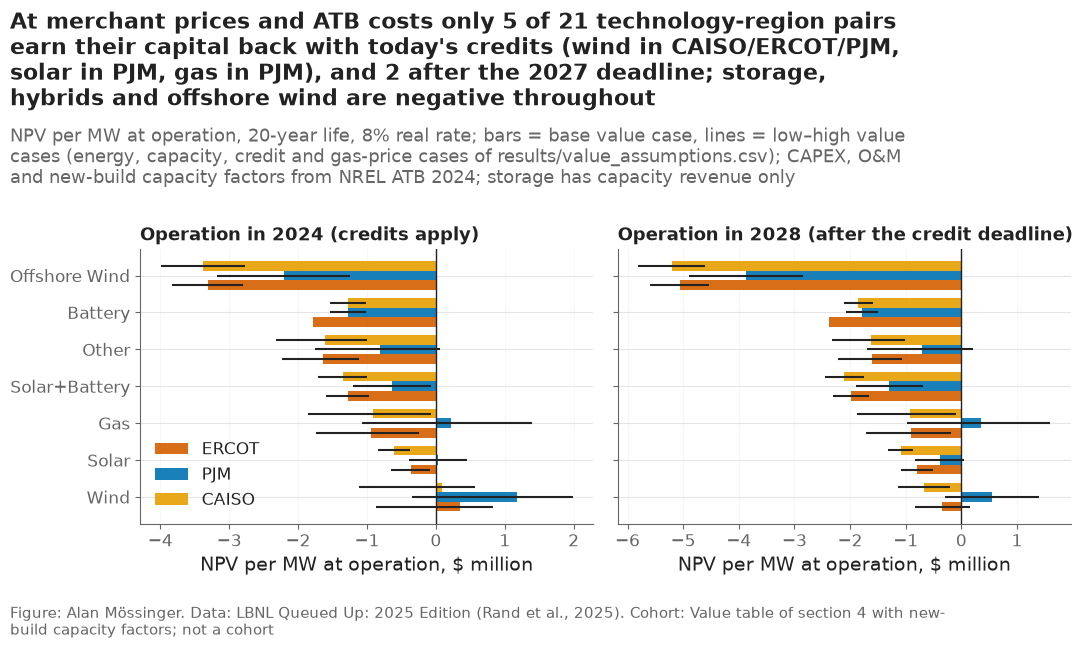

Break-even flat price against the price the table gives, $/MWh, operation in 2024:


breakeven_price_base               captured_price_base            
region                       CAISO  ERCOT    PJM               CAISO ERCOT   PJM
tech                                                                            
Battery                        NaN    NaN    NaN                 NaN   NaN   NaN
Gas                           80.2   80.2   80.2                57.7  37.2  51.8
Offshore Wind                126.8  126.8  126.8                46.3  31.6  43.6
Other                        109.2  109.2  109.2                51.7  33.5  46.6
Solar                         56.8   56.8   56.8                34.7  29.8  39.5
Solar+Battery                 96.6   96.6   96.6                45.1  31.6  43.4
Wind                          50.8   50.8   50.8                66.4  57.3  67.8

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True)
order = ["Wind", "Solar", "Gas", "Solar+Battery", "Other", "Battery", "Offshore Wind"]
NPV_COLS = ["npv_per_mw_low", "npv_per_mw_base", "npv_per_mw_high"]
width = 0.26
for ax, cod_year in zip(axes, [2024, 2028]):
    at = npv_table[npv_table["cod_year"] == cod_year].set_index(["tech", "region"])[NPV_COLS] / 1e6
    y = np.arange(len(order))
    for k, region in enumerate(["ERCOT", "PJM", "CAISO"]):
        part = at.xs(region, level="region").reindex(order)
        yy = y + (k - 1) * width
        ax.barh(yy, part["npv_per_mw_base"], height=width, color=plots.region_color(region), alpha=0.9, label=region)
        ax.hlines(yy, part["npv_per_mw_low"], part["npv_per_mw_high"], color=plots.INK, lw=1.5)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(order)
    ax.set_title(f"Operation in {cod_year}" + (" (credits apply)" if cod_year <= CREDIT_LAST_COD_YEAR else " (after the credit deadline)"), fontsize=13, loc="left")
    ax.set_xlabel("NPV per MW at operation, $ million")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(loc="lower left", frameon=False)
pos = {y: npv_table[(npv_table["cod_year"] == y) & (npv_table["npv_per_mw_base"] > 0)] for y in (2024, 2028)}
positives_2024 = ", ".join(f"{t.lower() if t != 'Other' else 'other'} in {'/'.join(sorted(g['region']))}" for t, g in pos[2024].groupby("tech", sort=False))
plots.finish(fig,
             f"At merchant prices and ATB costs only {len(pos[2024])} of 21 technology-region pairs earn their capital back with today's credits "
             f"({positives_2024}), and {len(pos[2028])} after the 2027 deadline; storage, hybrids and offshore wind are negative throughout",
             "NPV per MW at operation, 20-year life, 8% real rate; bars = base value case, lines = low–high value cases (energy, capacity, credit and gas-price "
             "cases of results/value_assumptions.csv); CAPEX, O&M and new-build capacity factors from NREL ATB 2024; storage has capacity revenue only",
             "Value table of section 4 with new-build capacity factors; not a cohort")
plots.save_fig(fig, "F26_npv_per_mw", "Net present value per MW at operation by technology and region for a plant entering operation in 2024 (credits apply) and 2028 (after the credit deadline), 20-year life, 8% real discount rate, low and high value cases as lines; revenue from the value table with new-build capacity factors, capital and O&M from NREL ATB 2024.", NOTEBOOK)
plt.show()
be = npv_table[npv_table["cod_year"] == 2024].pivot(index="tech", columns="region", values=["breakeven_price_base", "captured_price_base"]).round(1)
print("Break-even flat price against the price the table gives, $/MWh, operation in 2024:")
be

**Reading this.** Once capital is counted, the value index of section 4 turns into a short list. For a plant entering operation in 2024, with today's credits, only five of the 21 technology-region pairs have a positive base-case NPV per MW: wind in PJM ($1.18 million per MW), ERCOT ($0.34M) and CAISO ($0.09M), gas in PJM ($0.22M) and solar in PJM ($0.03M, in effect zero). Storage (−$1.3 to −$1.8M), hybrids (−$0.6 to −$1.4M) and offshore wind (−$2.2 to −$3.4M) are negative in every region, and so is everything in ERCOT and CAISO except wind. After the 2027 credit deadline only PJM wind ($0.55M) and PJM gas ($0.36M) stay positive. The low–high lines are wide: gas in PJM runs from −$0.9M to +$2.1M with the capacity and gas-price cases, so its sign is a bet on the capacity market.

The break-even flat price makes the same point in the unit a company negotiates in. A new solar plant needs $57/MWh over 20 years to earn 8% on its capital, wind $51, a combined cycle $80 (at $3.50 gas), a four-hour battery cannot be valued on capacity revenue alone, and a hybrid needs $97. The on-peak price the table captures for solar is $30–40/MWh, for wind $57–68. The gap is what a power purchase agreement, renewable energy certificates or a capacity contract must close, and none of those is in the public files. The decision this supports is therefore conditional and stated as such in notebook 16: at merchant prices, develop wind anywhere and gas or solar in PJM before 2027; develop the rest only with a contract above the break-even price.

### 8.1 Every test request valued at its decision date

For the gates of notebook 16 each request needs one number: its expected NPV at the day of the decision, `Σ_j P(operates in year j) × NPV_per_MW(COD = entry + j) × MW / (1 + r)^j`, with the level-repaired incidence curve of section 6 (and the raw curve beside it), its own state's capacity factor, and the three value cases. This is the value index of section 6 with capital cost, operating cost, discounting and a 20-year life put in.

In [12]:
npv_records = []
for i, (idx_, r) in enumerate(test.iterrows()):
    rec = {"project_key": str(r["project_key"]), "region": r["region"], "state": r["state"], "tech": r["tech"], "mw": r["mw"], "q_year": int(r["q_year"])}
    for case in CASES:
        per_mw = np.array([npv_parts(r["region"], r["tech"], int(r["q_year"]) + j, case, RATE)[0] for j in range(1, WINDOW + 1)])
        discount = (1 + RATE) ** np.arange(1, WINDOW + 1)
        for version, P in [("raw", P_raw), ("recalibrated", P_recal)]:
            increments = np.diff(np.concatenate([[0.0], P[i]]))
            rec[f"expected_npv_{version}_{case}"] = float((increments * per_mw / discount).sum() * r["mw"])
        rec[f"npv_per_mw_if_built_year3_{case}"] = float(per_mw[2])
    npv_records.append(rec)
npv_by_request = pd.DataFrame(npv_records)
npv_by_request.to_csv(paths.RESULTS / "npv_by_request.csv", index=False)
positive = npv_by_request["npv_per_mw_if_built_year3_base"] > 0
print(f"{len(npv_by_request):,} requests valued; share whose plant would have a positive base-case NPV if built three years after entry: {positive.mean():.1%} "
      f"(by region: {npv_by_request.groupby('region')['npv_per_mw_if_built_year3_base'].apply(lambda s: (s > 0).mean()).round(2).to_dict()})")
print("expected NPV at entry (probability-weighted, discounted), level repaired, base case, $ million:")
(npv_by_request["expected_npv_recalibrated_base"] / 1e6).describe().round(2)

2,268 requests valued; share whose plant would have a positive base-case NPV if built three years after entry: 32.5% (by region: {'CAISO': 0.07, 'ERCOT': 0.22, 'PJM': 0.42})
expected NPV at entry (probability-weighted, discounted), level repaired, base case, $ million:


count    2268.00
mean       -7.29
std        22.46
min      -270.20
25%        -9.12
50%        -0.34
75%        -0.03
max        68.77
Name: expected_npv_recalibrated_base, dtype: float64

**Reading this.** Probability-weighted and discounted to the day of the request, the median test request has an expected NPV of −$0.3 million in the base case and a mean of −$7 million, because most requests are solar, storage or hybrids in ERCOT and CAISO, whose plants have a negative NPV at merchant prices, and because a request's probability of operating is low. Only 42% of PJM's, 22% of ERCOT's and 7% of CAISO's requests would have a positive NPV per MW if built three years after entry. Wind is the exception in every region (median expected NPV +$14 million in ERCOT and PJM, +$0.9 million in CAISO) and PJM gas sits at zero. This is the quantity the entry gate of notebook 16 tests against the cost of the next study and deposit; the same arithmetic two years in, with the landmark probabilities, is the review gate. Dollar years differ between the ATB costs (2022) and the value table (each year's prices), a gap of a few percent that does not change any sign above.

## 9. Checks

In [13]:
checks = pd.DataFrame([
    {"check": "every value input has a source or an assumption row", "value": len(assumptions), "pass": len(assumptions) >= 10},
    {"check": "capacity revenue parsed for 20 years", "value": len(rpm), "pass": len(rpm) == 20},
    {"check": "ELCC ratings parsed for 18 classes", "value": len(elcc), "pass": len(elcc) == 18},
    {"check": "no missing value in the value table", "value": int(value_table[CASES].isna().sum().sum()), "pass": not value_table[CASES].isna().any().any()},
    {"check": "every test request valued", "value": len(valued), "pass": len(valued) == len(test)},
    {"check": "ATB costs read for every technology group", "value": len(atb), "pass": len(atb) == len(TECHS) and atb["capex_per_kw"].notna().all()},
    {"check": "NPV table complete (3 regions × 7 technologies × 13 COD years × 3 cases)", "value": len(npv_table), "pass": len(npv_table) == 3 * 7 * 13 and npv_table.filter(like="npv_per_mw").notna().all().all()},
    {"check": "every test request has an expected NPV", "value": len(npv_by_request), "pass": len(npv_by_request) == len(test) and npv_by_request.filter(like="expected_npv").notna().all().all()},
    {"check": "F26 saved as PNG and SVG", "value": 2, "pass": (paths.FIGURES / "F26_npv_per_mw.png").exists() and (paths.FIGURES / "F26_npv_per_mw.svg").exists()},
    {"check": "F13 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F13_expected_mw_and_value.png").exists() and (paths.FIGURES / "F13_expected_mw_and_value.svg").exists()},
])
checks.to_csv(paths.RESULTS / "value_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.3 min


,check,value,pass
0,every value input has a source or an assumptio...,22,True
1,capacity revenue parsed for 20 years,20,True
2,ELCC ratings parsed for 18 classes,18,True
3,no missing value in the value table,0,True
4,every test request valued,2268,True
5,ATB costs read for every technology group,7,True
6,NPV table complete (3 regions × 7 technologies...,273,True
7,every test request has an expected NPV,2268,True
8,F26 saved as PNG and SVG,2,True
9,F13 saved as PNG and SVG,2,True


## Takeaways

- Every value input is parsed from a public file (EIA hub prices, PJM capacity revenue and ELCC ratings, EIA generation and capacity, LBNL PJM costs) or stated with a range and a source in `results/value_assumptions.csv`; the index has no discounting or financing and says so.
- A MW online in 2024 is worth, in the base case, about $249,000 a year for gas in PJM, $135,000 for wind and $62,000 for solar; CAISO's capacity price and the ERCOT price after 2019 are assumptions to verify.
- Interconnection cost exposure peaks at $82/kW for 20–100 MW requests (PJM median); the sunk cost to the next gate is small except for the smallest requests.
- The 2017–2019 cohort: 29.2 GW expected online within five years (raw), 25.2 GW after the level repair, 18.8 GW realised — the level error in megawatts.
- The order of requests by expected value is almost insensitive to the value case (Spearman ≥ 0.97); the probabilities drive the book, the assumptions drive its worth.
- **What goes to the report:** F13; the value and cost tables with their assumption list; the MW-online gap as the portfolio-scale statement of the calibration problem.
- **With capital counted (section 8, F26):** at merchant prices and NREL ATB costs only five of 21 technology-region pairs have a positive NPV per MW with today's credits (wind everywhere, gas and solar in PJM), two after the 2027 deadline; storage, hybrids and offshore wind are negative throughout. Break-even flat prices are $57/MWh for solar, $51 for wind and $80 for gas against captured prices of $30–68: the gap is what a contract must close. The median test request's expected NPV at entry is −$0.3 million; wind is the exception (+$14 million in ERCOT and PJM). These feed the gates of notebook 16; F26 and the break-even table go to the report's "what a project is worth" section.